# 02 · Evaluation, visualisation and interpretability (Sachin)

Phase 1 (classical ML) results for Next Day Wildfire Spread (Huot et al., 2022).

**Inputs** (made by teammates' scripts, not by this notebook):
- `reports/preds/{model}.npz`: `y_true` and `y_prob`, each of shape (1689, 64, 64), one map per test patch,
  in the same order as `load_split("test")`. Labels are 1 = fire, 0 = no fire, -1 = unknown.
- `reports/results.csv`: test metrics per model from `src/evaluate.py`. `threshold` was chosen on the **eval** split.
- `reports/best_params.json`: hyperparameters of the tuned XGBoost / LightGBM.

**Rule used everywhere:** pixels with label -1 are dropped before any metric or plot.

**Outputs:** `reports/figures/eval_*.png` and `reports/results_table.md`.

In [1]:
import os
from pathlib import Path

# The notebook lives in notebooks/; move to the repo root so `src` imports and relative paths work.
if Path.cwd().name == "notebooks":
    os.chdir("..")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import precision_recall_curve, roc_curve

SEED = 0
PREDS = Path("reports/preds")
FIGS = Path("reports/figures")
FIGS.mkdir(parents=True, exist_ok=True)

# Model name in files -> label shown in plots. Order = baselines first, tuned models last.
MODELS = {
    "persistence": "Persistence",
    "logreg_raw": "Logistic reg. (raw)",
    "rf_raw": "Random forest (raw)",
    "xgb_raw": "XGBoost (raw)",
    "xgboost": "XGBoost (tuned, all features)",
    "lightgbm": "LightGBM (tuned, all features)",
}
# Fixed colour per model (colour-blind-checked palette), dashed = baseline, solid = our tuned models.
COLORS = dict(zip(MODELS, ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e34948", "#6250d6"]))
STYLE = {m: "-" if m in ("xgboost", "lightgbm") else "--" for m in MODELS}

plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 200, "savefig.bbox": "tight",
                     "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
                     "grid.alpha": 0.3, "font.size": 10})

results = pd.read_csv("reports/results.csv").set_index("model")
results

,pr_auc,roc_auc,precision,recall,f1,threshold,best_f1,best_f1_threshold,recall_at_1fpr,recall_at_5fpr,n_pixels,fire_rate
model,,,,,,,,,,,,
persistence,0.1065,0.6333,0.3572,0.2728,0.3093,0.5000,0.3093,1.0000,0.2728,0.2728,6727699,0.0125
logreg_raw,0.1457,0.7985,0.3776,0.2658,0.3120,0.9358,0.3128,0.9262,0.2813,0.3190,6727699,0.0125
rf_raw,0.1565,0.8163,0.3712,0.2699,0.3125,0.8474,0.3141,0.8804,0.2785,0.3622,6727699,0.0125
xgb_raw,0.1455,0.7955,0.3373,0.2570,0.2917,0.8744,0.2962,0.9053,0.2666,0.3752,6727699,0.0125
xgboost,0.2559,0.9032,0.2570,0.5045,0.3405,0.9237,0.3587,0.9544,0.3904,0.6748,6727699,0.0125
lightgbm,0.2519,0.8959,0.2527,0.5143,0.3389,0.9158,0.3584,0.9500,0.3893,0.6696,6727699,0.0125


In [2]:
def load_preds(name):
    """Return y_true and y_prob maps (1689, 64, 64) for one model."""
    d = np.load(PREDS / f"{name}.npz")
    return d["y_true"], d["y_prob"]


# All models were scored on the same test pixels, so we read the labels once.
y_map, _ = load_preds("xgboost")
labelled = y_map != -1                      # mask of pixels we are allowed to score
y_flat = y_map[labelled].astype(int)        # 1-D vector of 0/1 labels
probs = {m: load_preds(m)[1][labelled] for m in MODELS}   # 1-D probabilities, same order as y_flat

fire_rate = y_flat.mean()
print(f"test pixels: {y_map.size:,} | labelled: {labelled.sum():,} | dropped (-1): {(~labelled).sum():,}")
print(f"next-day fire rate among labelled pixels: {fire_rate:.4f}  (about 1 fire pixel in {1 / fire_rate:.0f})")

test pixels: 6,918,144 | labelled: 6,727,699 | dropped (-1): 190,445
next-day fire rate among labelled pixels: 0.0125  (about 1 fire pixel in 80)


## 1 · Precision-recall and ROC curves (test split)

**Why PR first.** Only 1.25% of labelled test pixels burn. ROC uses the false positive rate FP / (all no-fire pixels);
with 79 no-fire pixels per fire pixel, a model can raise many false alarms while FPR stays small, so ROC AUC looks good.
Precision = TP / (TP + FP) is hit directly by those false alarms, so PR AUC is the main metric here
(as in Huot et al. 2022). A random model gets PR AUC ≈ fire rate (0.0125) but ROC AUC = 0.5.

PR AUC is computed as average precision (`average_precision_score`), the same number as in `results.csv`.
The dot on each PR curve is the operating point at the threshold chosen on the **eval** split (best eval F1),
i.e. what the model would actually do on unseen data.

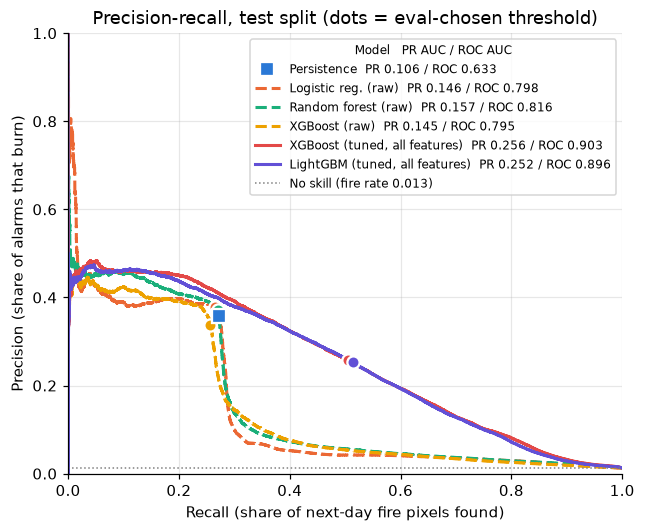

In [3]:
fig, ax = plt.subplots(figsize=(6.5, 5.2))
for m, label in MODELS.items():
    r = results.loc[m]
    legend = f"{label}  PR {r.pr_auc:.3f} / ROC {r.roc_auc:.3f}"
    if m == "persistence":
        # Persistence outputs only 0 or 1, so it has ONE operating point, not a curve
        # (a straight line between PR points would overstate it).
        ax.plot(r.recall, r.precision, "s", ms=9, color=COLORS[m], mec="white", mew=1.5, zorder=6, label=legend)
        continue
    precision, recall, _ = precision_recall_curve(y_flat, probs[m])
    ax.plot(recall, precision, STYLE[m], color=COLORS[m], lw=2, label=legend)
    # Operating point at the eval-chosen threshold (precision/recall columns of results.csv).
    ax.plot(r.recall, r.precision, "o", ms=8, color=COLORS[m], mec="white", mew=1.5, zorder=5)

ax.axhline(fire_rate, color="grey", lw=1, ls=":", label=f"No skill (fire rate {fire_rate:.3f})")
ax.set(xlabel="Recall (share of next-day fire pixels found)", ylabel="Precision (share of alarms that burn)",
       xlim=(0, 1), ylim=(0, 1), title="Precision-recall, test split (dots = eval-chosen threshold)")
ax.legend(fontsize=8, loc="upper right", title="Model   PR AUC / ROC AUC", title_fontsize=8)
fig.savefig(FIGS / "eval_pr_curves.png")
plt.show()

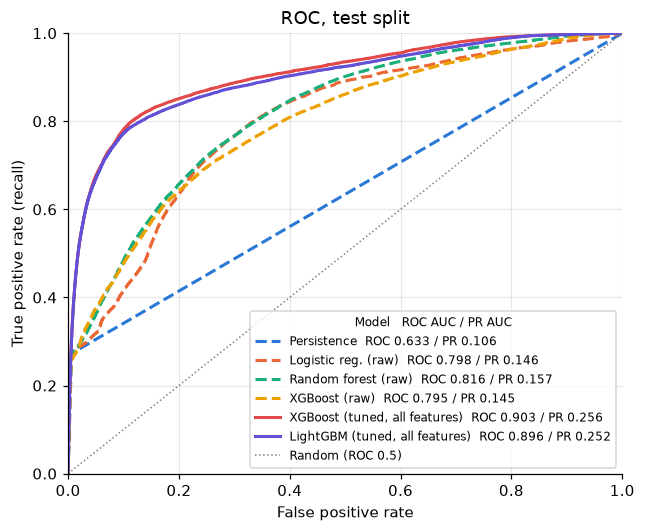

In [4]:
fig, ax = plt.subplots(figsize=(6.5, 5.2))
for m, label in MODELS.items():
    fpr, tpr, _ = roc_curve(y_flat, probs[m])
    r = results.loc[m]
    ax.plot(fpr, tpr, STYLE[m], color=COLORS[m], lw=2, label=f"{label}  ROC {r.roc_auc:.3f} / PR {r.pr_auc:.3f}")

ax.plot([0, 1], [0, 1], color="grey", lw=1, ls=":", label="Random (ROC 0.5)")
ax.set(xlabel="False positive rate", ylabel="True positive rate (recall)", xlim=(0, 1), ylim=(0, 1),
       title="ROC, test split")
ax.legend(fontsize=8, loc="lower right", title="Model   ROC AUC / PR AUC", title_fontsize=8)
fig.savefig(FIGS / "eval_roc_curves.png")
plt.show()

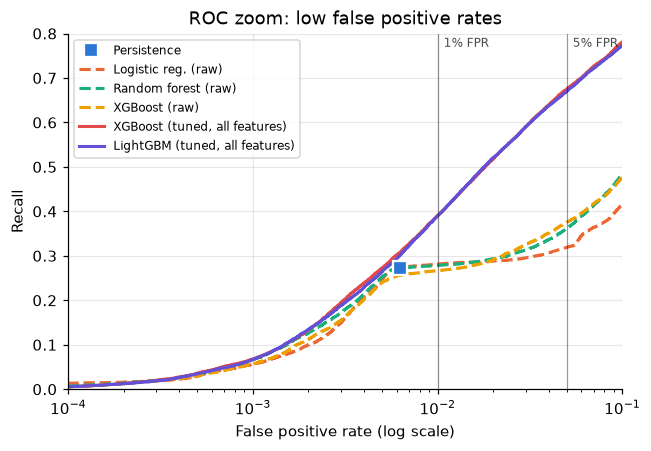

In [5]:
# The low-FPR end is where a fire agency would operate, so zoom in on FPR <= 10% (log x-axis).
fig, ax = plt.subplots(figsize=(6.5, 4.2))
for m, label in MODELS.items():
    fpr, tpr, _ = roc_curve(y_flat, probs[m])
    if m == "persistence":  # single operating point (see PR plot)
        ax.plot(fpr[1], tpr[1], "s", ms=9, color=COLORS[m], mec="white", mew=1.5, zorder=6, label=label)
        continue
    keep = fpr > 0  # log axis cannot show FPR = 0
    ax.plot(fpr[keep], tpr[keep], STYLE[m], color=COLORS[m], lw=2, label=label)
for x in (0.01, 0.05):  # the two fixed false positive rates reported in the results table
    ax.axvline(x, color="black", lw=0.8, alpha=0.4)
    ax.text(x * 1.08, 0.77, f"{x:.0%} FPR", fontsize=8, alpha=0.7)
ax.set(xscale="log", xlim=(1e-4, 0.1), ylim=(0, 0.8), xlabel="False positive rate (log scale)",
       ylabel="Recall", title="ROC zoom: low false positive rates")
ax.legend(fontsize=8, loc="upper left")
fig.savefig(FIGS / "eval_roc_lowfpr.png")
plt.show()

**Reading the curves**
- The two tuned models (solid) are clearly above every baseline across the whole PR curve:
  PR AUC 0.256 (XGBoost) and 0.252 (LightGBM) against 0.146-0.157 for models trained on the 12 raw channels.
  Engineered fire-neighbourhood features account for most of this gap (see Task 4).
- XGBoost and LightGBM are almost on top of each other, so the choice of boosting library matters far less than the features.
- Persistence is a single point (square; it outputs only 0 or 1): it finds 27% of next-day fire at 36% precision
  with a false positive rate of only 0.6%.
- The raw-channel baselines collapse right after recall ≈ 0.27: they rank pixels already burning on day t first
  ("fire stays where it is") and have almost no signal for new fire, so their precision drops to ~5%.
  Their eval-chosen operating points sit on top of persistence. The tuned models keep ≈0.25-0.45 precision up to recall 0.5,
  i.e. they also find *new* fire pixels near the front.
- Low-FPR zoom: at persistence's own false positive rate (0.62%) tuned XGBoost finds 31% of fire pixels vs 27%;
  at 1% / 5% FPR it finds 39% / 67%, while persistence stays at 27% (it has no other operating point).
- The eval-chosen threshold of the tuned models sits at higher recall (≈0.50) and lower precision (≈0.26) than the baselines,
  which is where their F1 is highest.
- ROC AUC is 0.80-0.90 for every learned model while PR AUC stays below 0.26. This is the class-imbalance effect explained above.

## 2 · Results table

Built from `reports/results.csv` and written to `reports/results_table.md`.
Precision, recall and F1 are at the threshold chosen on the **eval** split (not tuned on test).
Recall @ 1% / 5% FPR = share of fire pixels found when we allow 1% / 5% of no-fire pixels to be false alarms.

The paper rows are PR AUC from Huot et al. (2022) for reference only. They are not a like-for-like comparison:
their logistic regression and random forest also get the 8 neighbouring pixels of every channel as input,
and their numbers come from their own pipeline. The CNN is a convolutional autoencoder that sees the whole 64×64 patch.

In [6]:
COLUMNS = {  # results.csv column -> table header
    "pr_auc": "PR AUC", "roc_auc": "ROC AUC", "precision": "Precision", "recall": "Recall", "f1": "F1",
    "recall_at_1fpr": "Recall @ 1% FPR", "recall_at_5fpr": "Recall @ 5% FPR",
}
table = results.loc[list(MODELS), list(COLUMNS)].rename(columns=COLUMNS)
table.index = [MODELS[m] for m in table.index]
table.index.name = "Model"

# PR AUC reported by Huot et al. (2022); their LR / RF also use the 8 neighbouring pixels.
PAPER = {"Persistence": 0.115, "Logistic regression (+ 8 neighbours)": 0.198,
         "Random forest (+ 8 neighbours)": 0.225, "CNN autoencoder": 0.284}


def to_markdown(df, best_col_max=True):
    """Small markdown writer (avoids an extra dependency). Bold = best value in each column."""
    lines = ["| " + " | ".join([df.index.name] + list(df.columns)) + " |",
             "|" + "---|" + "---:|" * len(df.columns)]
    best = df.max() if best_col_max else None
    for name, row in df.iterrows():
        cells = [f"**{v:.3f}**" if v == best[c] else f"{v:.3f}" for c, v in row.items()]
        lines.append("| " + " | ".join([name] + cells) + " |")
    return "\n".join(lines)


md_text = "\n".join([
    "# Phase 1 results (test split, 1,689 patches, 6.73M labelled pixels, 1.25% fire)",
    "",
    "Precision / recall / F1 at the decision threshold chosen on the eval split. Bold = best per column.",
    "",
    to_markdown(table),
    "",
    "## Reference: Huot et al. (2022), PR AUC on the same test split",
    "",
    "| Model | PR AUC |",
    "|---|---:|",
    *[f"| {k} | {v:.3f} |" for k, v in PAPER.items()],
    "",
    "Paper LR / RF also use the 8 neighbouring pixels of every channel; numbers are from their pipeline, "
    "so they are a reference point, not a like-for-like comparison.",
    "",
])
Path("reports/results_table.md").write_text(md_text)
print(md_text)

# Phase 1 results (test split, 1,689 patches, 6.73M labelled pixels, 1.25% fire)

Precision / recall / F1 at the decision threshold chosen on the eval split. Bold = best per column.

| Model | PR AUC | ROC AUC | Precision | Recall | F1 | Recall @ 1% FPR | Recall @ 5% FPR |
|---|---:|---:|---:|---:|---:|---:|---:|
| Persistence | 0.106 | 0.633 | 0.357 | 0.273 | 0.309 | 0.273 | 0.273 |
| Logistic reg. (raw) | 0.146 | 0.798 | **0.378** | 0.266 | 0.312 | 0.281 | 0.319 |
| Random forest (raw) | 0.157 | 0.816 | 0.371 | 0.270 | 0.312 | 0.279 | 0.362 |
| XGBoost (raw) | 0.145 | 0.795 | 0.337 | 0.257 | 0.292 | 0.267 | 0.375 |
| XGBoost (tuned, all features) | **0.256** | **0.903** | 0.257 | 0.504 | **0.341** | **0.390** | **0.675** |
| LightGBM (tuned, all features) | 0.252 | 0.896 | 0.253 | **0.514** | 0.339 | 0.389 | 0.670 |

## Reference: Huot et al. (2022), PR AUC on the same test split

| Model | PR AUC |
|---|---:|
| Persistence | 0.115 |
| Logistic regression (+ 8 neighbours) | 0.198 |
|

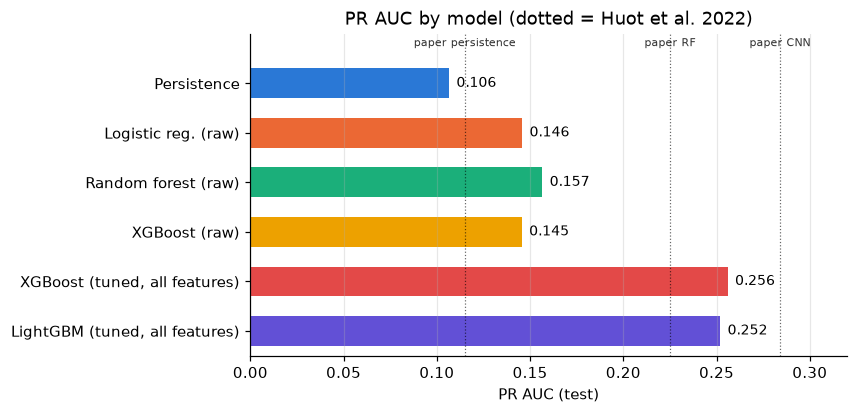

In [7]:
# Same table as a quick bar chart of the two threshold-free metrics plus the paper's PR AUC (for slides).
fig, ax = plt.subplots(figsize=(7, 3.8))
names = list(MODELS)
y = np.arange(len(names))
ax.barh(y, results.loc[names, "pr_auc"], color=[COLORS[m] for m in names], height=0.6)
for i, m in enumerate(names):
    ax.text(results.loc[m, "pr_auc"] + 0.004, i, f"{results.loc[m, 'pr_auc']:.3f}", va="center", fontsize=9)
for v, lab in [(0.115, "paper persistence"), (0.225, "paper RF"), (0.284, "paper CNN")]:
    ax.axvline(v, color="black", lw=0.8, ls=":", alpha=0.6)
    ax.text(v, -0.75, lab, fontsize=7.5, ha="center", alpha=0.8)
ax.set_yticks(y, [MODELS[m] for m in names])
ax.set_ylim(len(names) - 0.5, -1.0)  # top-to-bottom order, with room above the bars for the paper labels
ax.set(xlabel="PR AUC (test)", xlim=(0, 0.32), title="PR AUC by model (dotted = Huot et al. 2022)")
ax.grid(axis="y", visible=False)
fig.savefig(FIGS / "eval_pr_auc_bars.png")
plt.show()

**Reading the table**
- Tuned XGBoost is best on every threshold-free metric (PR AUC 0.256, ROC AUC 0.903, recall 39% @ 1% FPR, 67% @ 5% FPR).
  LightGBM is within 0.004 PR AUC, i.e. a tie.
- At the eval-chosen threshold the tuned models trade precision for recall: they find about 50% of next-day fire
  (vs 26-27% for the baselines) at 25-26% precision, giving the best F1 (0.34).
- The raw baselines do no better than persistence on F1 (0.29-0.31 vs 0.31) even though their PR AUC is higher:
  the extra ranking quality is all at recall levels persistence cannot reach.
- Against the paper: our persistence (0.106) is close to theirs (0.115). Our tuned XGBoost (0.256) is above their
  neighbour-feature random forest (0.225) but below their CNN (0.284): engineered features close most of the gap,
  and the remaining gap is the spatial context the Phase 2 CNN / U-Net is meant to capture.
- `best_f1` in results.csv (0.359 for XGBoost) is the F1 if the threshold were tuned on test; the gap to 0.341
  shows the eval-chosen threshold transfers well.